# Annotationspräzision – Inter-Rater-Reliabilität
Analysiert auf Basis eines frischen API-Requests.
Dokumentation: `docs/exp_Annotation_correctness.md`

In [1]:
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')

import annotation_analysis as aa
from annotation_analysis import (
    compute_icc, compute_std_by_label,
    label_to_region, spine_labels, spine_regions,
)

os.makedirs('output', exist_ok=True)

%load_ext autoreload
%aimport annotation_analysis
%autoreload 1

## Schritt 0 – Datenvorbereitung

### 0.1 API-Request

In [2]:
api_url = 'https://xray-api.renecol.org'
token = 'DLkevyX247TBgr5Jl7fvGRSO03k3YG'  # Token hier einfügen

response = requests.get(
    headers={'Authorization': 'Bearer ' + token},
    url=api_url + '/api/imagedata/',
    params={'detailed': True, 'complete': True}
).json()

df = pd.DataFrame(response)
print(f'{len(df)} Bilder geladen, {df["measure_dataset"].map(len).sum()} Messungen gesamt')

860 Bilder geladen, 1117 Messungen gesamt


### 0.2 Transformation zu df4d
Methodik aus `reconstructing_spline.ipynb`; `rater_name` und `rater_id` werden aus `measure_dataset.user` extrahiert.

In [3]:
df4d = aa.build_df4d(df)
print(f'df4d: {len(df4d)} Messungen')
print(f'Spalten: {list(df4d.columns)}')

df4d: 1117 Messungen
Spalten: ['id', 'uuid', 'img', 'patient_id', 'referring_patient', 'img_type', 'acquisition_date', 'measure_dataset_index', 'rater_name', 'rater_id', 'm_uuid', 'xray_measurement_data']


### 0.3 Label-Fehlerkorrektur → df4d_corrected
k-Means-Clustering der Node-Positionen pro Bild (Logik in `annotation_analysis.detect_label_errors`).

In [4]:
label_errors = aa.detect_label_errors(df4d)

n_shift = (label_errors['error'] == 'shift').sum()
n_empty = (label_errors['error'] == 'empty').sum()
print(f'Shift-Fehler: {n_shift}, Leere Messungen: {n_empty}')
label_errors.head()

Shift-Fehler: 73, Leere Messungen: 5


,df_idx,m_uuid,error,shift
0,20,56c1b8b1-cee1-463c-a68e-48f74a3f3af7,shift,-1
1,504,d3c0b8a3-c4b0-4a91-a029-93fc3cd007f1,shift,1
2,37,0310d313-6c62-4c51-b357-7d89c18b82ff,shift,-1
3,56,6a57e0c3-8fe6-44b4-944f-7a55103cc13e,shift,-1
4,58,9925e6ec-a230-4d01-a58e-dcba6ec1177f,shift,-1


In [35]:
df4d_corrected = aa.apply_label_corrections(df4d, label_errors)
df4d_corrected.to_pickle('data/df4d_corrected_spine_measurements.pkl')
print(f'df4d_corrected: {(label_errors["error"] == "shift").sum()} Messungen korrigiert')

df4d_corrected: 73 Messungen korrigiert


### 0.4 Rater-Struktur validieren

In [6]:
# Anzahl distincter Rater pro Bild
raters_per_image = df4d.groupby('id').agg(
    n_measurements=('rater_id', 'count'),
    n_distinct_raters=('rater_id', 'nunique')
)

print('Verteilung distincter Rater pro Bild:')
print(raters_per_image['n_distinct_raters'].value_counts().sort_index().to_string())

# Bilder, bei denen mehrere Messungen vom gleichen Rater stammen
intra_rater_images = raters_per_image[
    raters_per_image['n_distinct_raters'] < raters_per_image['n_measurements']
]
print(f'\nBilder mit Intra-Rater-Messungen (gleicher Rater >1x): {len(intra_rater_images)}')

# Eligible: >=2 verschiedene Rater
eligible_image_ids = set(
    raters_per_image[raters_per_image['n_distinct_raters'] >= 2].index
)
print(f'Bilder mit >=2 verschiedenen Ratern (eligible): {len(eligible_image_ids)}')

Verteilung distincter Rater pro Bild:
n_distinct_raters
1     96
2    142
3    243
4      2

Bilder mit Intra-Rater-Messungen (gleicher Rater >1x): 0
Bilder mit >=2 verschiedenen Ratern (eligible): 387


### 0.5 Analyse-DataFrames aufbauen

In [7]:
nodes_df_raw       = aa.build_nodes_df(df4d)
nodes_df_corrected = aa.build_nodes_df(df4d_corrected)
angles_df          = aa.build_angles_df(df4d_corrected, include_reconstructed=True)

print(f'nodes_df_raw:       {len(nodes_df_raw)} Zeilen')
print(f'nodes_df_corrected: {len(nodes_df_corrected)} Zeilen')
print(f'angles_df:          {len(angles_df)} Zeilen, cobbTypes: {angles_df["cobbType"].value_counts().to_dict()}')

nodes_df_raw:       10587 Zeilen
nodes_df_corrected: 10585 Zeilen
angles_df:          15700 Zeilen, cobbTypes: {'reconstructed_segmental': 6502, 'Cobb-segmental': 4179, 'Spline': 1994, 'reconstructed_regional': 1777, 'Cobb-regional': 1248}


In [8]:
# compute_icc, compute_std_by_label, label_to_region importiert aus annotation_analysis
print('Alle Analysefunktionen geladen aus annotation_analysis.py')
print(f'Spine-Regionen: {spine_regions}')

Alle Analysefunktionen geladen aus annotation_analysis.py
Spine-Regionen: {'CT': [0, 9], 'PT': [10, 12], 'MT': [13, 18], 'TL': [19, 20], 'LU': [21, 25]}


---
## Schritt 1 – Node-Präzision (korrigierter Datensatz)
**Forschungsfrage:** Wie konsistent platzieren verschiedene Annotator\*innen die Spline-Nodes für denselben Wirbelkörper?

### 1.1 Deskriptive Statistik

Tab. 1a – Deskriptive Statistik Node-Positionen (nach Korrektur):
                x_mean  x_std  y_mean  y_std  n_images
vertebra_label                                        
C5               617.8    3.2    94.8    0.9       2.0
C6               498.1    2.8   120.9    4.5       6.0
C7               520.1    4.1   130.7   13.5      16.0
T1               529.5    4.2   142.7   12.7      20.0
T2               532.7    4.1   158.9   13.0      20.0
T3               536.7    2.5   167.7    4.9      20.0
T4               545.0    2.8   185.4    9.5      22.0
T5               552.5    2.8   183.0    9.5      25.0
T6               559.7    3.0   176.8    9.3      30.0
T7               566.4    2.8   158.5    8.1      41.0
T8               538.0    2.3   122.8    6.1      68.0
T9               513.5    2.1   100.0    5.3     128.0
T10              505.9    2.8    96.6    5.4     239.0
T11              507.1    2.8   115.8    5.4     337.0
T12              508.1    2.9   154.2    5.2     380.0

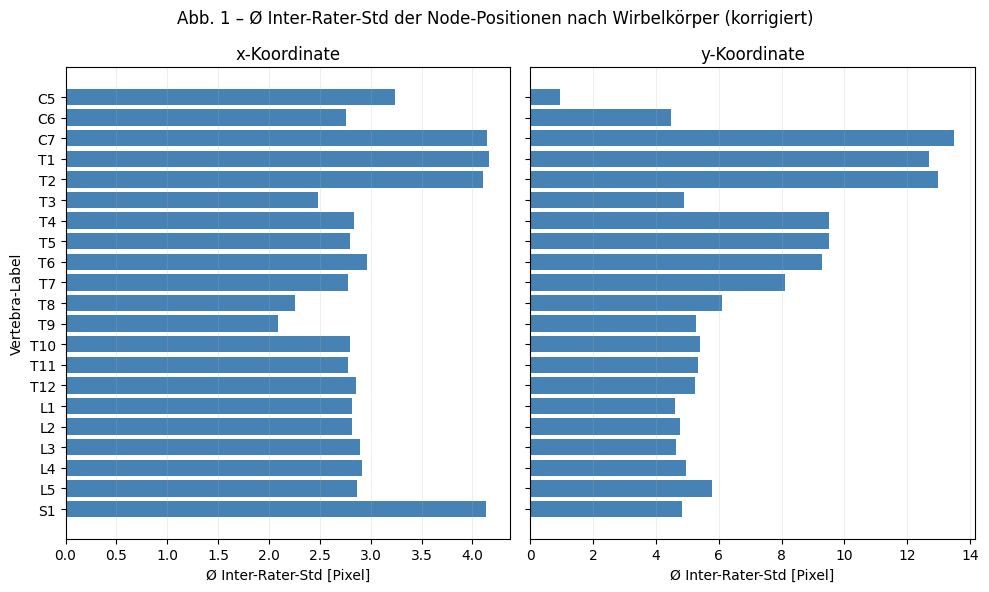

In [8]:
nodes_eligible = nodes_df_corrected[nodes_df_corrected['image_id'].isin(eligible_image_ids)]

# Std erst pro (image_id, vertebra_label) über Rater, dann über Bilder mitteln.
# Direkte groupby('vertebra_label') würde Bild-zu-Bild-Variation einschließen
# (jedes Bild hat andere absolute Pixelkoordinaten).
within = (
    nodes_eligible
    .groupby(['vertebra_label', 'image_id'])
    .agg(x_mean=('x', 'mean'), x_std=('x', 'std'),
         y_mean=('y', 'mean'), y_std=('y', 'std'),
         n_raters=('x', 'count'))
    .reset_index()
)
within = within[within['n_raters'] >= 2]

desc_stats = (
    within.groupby('vertebra_label')
    .agg(
        x_mean  =('x_mean',  'mean'),
        x_std   =('x_std',   'mean'),   # Ø Inter-Rater-Std über Bilder
        y_mean  =('y_mean',  'mean'),
        y_std   =('y_std',   'mean'),
        n_images=('n_raters', 'count'), # Anzahl Bilder mit >=2 Ratern
    )
    .reindex(spine_labels)
    .dropna(how='all')
)

print('Tab. 1a – Deskriptive Statistik Node-Positionen (nach Korrektur):')
print(desc_stats.round(1).to_string())

# Heatmap der Std-Werte
fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=True)
for ax, coord, title in zip(axes, ['x', 'y'], ['x-Koordinate', 'y-Koordinate']):
    vals = desc_stats[f'{coord}_std'].dropna()
    ax.barh(vals.index[::-1], vals.values[::-1], color='steelblue')
    ax.set_xlabel('Ø Inter-Rater-Std [Pixel]')
    ax.set_title(title)
    ax.grid(axis='x', alpha=0.3)
axes[0].set_ylabel('Vertebra-Label')
fig.suptitle('Abb. 1 – Ø Inter-Rater-Std der Node-Positionen nach Wirbelkörper (korrigiert)', fontsize=12)
plt.tight_layout()
plt.savefig('output/node_std_by_vertebra.png', dpi=150)
plt.show()

### 1.2 ICC(2,1) pro Vertebra-Label

In [9]:
icc_rows = []
for label in spine_labels:
    label_data = nodes_eligible[nodes_eligible['vertebra_label'] == label]
    for coord in ['x', 'y']:
        res = compute_icc(label_data, 'image_id', 'rater_name', coord)
        icc_rows.append({'vertebra_label': label, 'coord': coord, **res})

icc_node_df = pd.DataFrame(icc_rows)

# Pivot für Tabelle
icc_pivot = icc_node_df.pivot(index='vertebra_label', columns='coord', values=['ICC', 'CI95_lower', 'CI95_upper', 'n'])
icc_pivot.columns = ['_'.join(col) for col in icc_pivot.columns]
icc_pivot = icc_pivot.reindex(spine_labels).dropna(how='all')

print('Tab. 1b – ICC(2,1) pro Vertebra-Label (korrigiert):')
print(icc_pivot[['ICC_x', 'CI95_lower_x', 'CI95_upper_x', 'n_x', 'ICC_y', 'CI95_lower_y', 'CI95_upper_y']].round(3).to_string())
icc_pivot.to_csv('output/icc_nodes_per_vertebra_corrected.csv')

Tab. 1b – ICC(2,1) pro Vertebra-Label (korrigiert):
                ICC_x  CI95_lower_x  CI95_upper_x    n_x  ICC_y  CI95_lower_y  CI95_upper_y
vertebra_label                                                                             
C0                NaN           NaN           NaN    0.0    NaN           NaN           NaN
C1                NaN           NaN           NaN    0.0    NaN           NaN           NaN
C2                NaN           NaN           NaN    0.0    NaN           NaN           NaN
C3                NaN           NaN           NaN    0.0    NaN           NaN           NaN
C4                NaN           NaN           NaN    0.0    NaN           NaN           NaN
C5                NaN           NaN           NaN    2.0    NaN           NaN           NaN
C6                NaN           NaN           NaN    6.0    NaN           NaN           NaN
C7              0.997         0.993         0.999   16.0  0.706         0.387         0.888
T1              0.997       

### 1.3 Aggregation nach Wirbelsäulenregion

ICC(2,1) nach Wirbelsäulenregion:
region coord   ICC  CI95_lower  CI95_upper   n
    CT     x 0.993       0.990       0.997  20
    CT     y 0.581       0.464       0.791  20
    PT     x 0.997       0.995       0.998  25
    PT     y 0.788       0.681       0.887  25
    MT     x 0.997       0.997       0.997 337
    MT     y 0.823       0.797       0.847 337
    TL     x 0.995       0.995       0.996 387
    TL     y 0.835       0.812       0.857 387
    LU     x 0.977       0.974       0.980 386
    LU     y 0.262       0.229       0.299 386


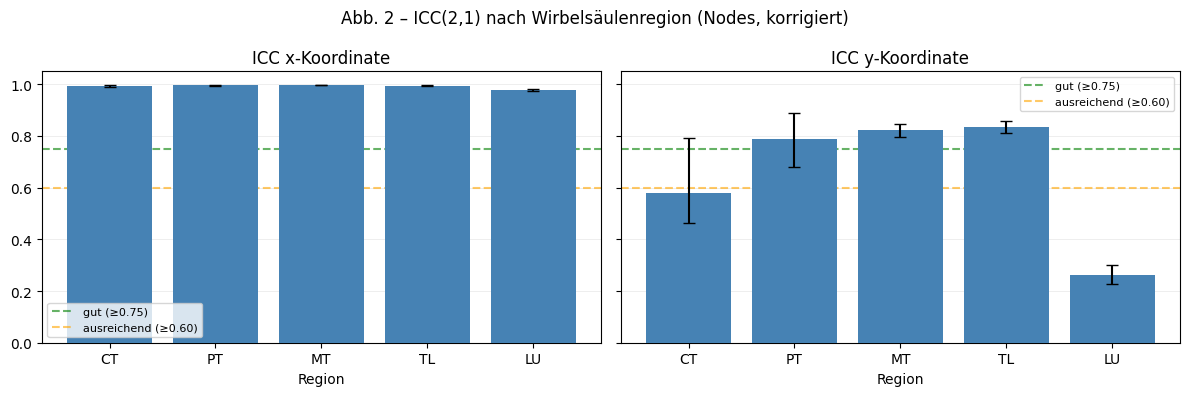

In [10]:
nodes_eligible['region'] = nodes_eligible['vertebra_label'].map(label_to_region)

region_icc_rows = []
for region in spine_regions:
    region_data = nodes_eligible[nodes_eligible['region'] == region]
    for coord in ['x', 'y']:
        res = compute_icc(region_data, 'image_id', 'rater_name', coord)
        region_icc_rows.append({'region': region, 'coord': coord, **res})

region_icc_df = pd.DataFrame(region_icc_rows)
print('ICC(2,1) nach Wirbelsäulenregion:')
print(region_icc_df.round(3).to_string(index=False))

# Balkendiagramm
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, coord in zip(axes, ['x', 'y']):
    sub = region_icc_df[region_icc_df['coord'] == coord].dropna(subset=['ICC'])
    ax.bar(sub['region'], sub['ICC'], color='steelblue', zorder=3)
    ax.errorbar(
        sub['region'], sub['ICC'],
        yerr=[sub['ICC'] - sub['CI95_lower'], sub['CI95_upper'] - sub['ICC']],
        fmt='none', color='black', capsize=4, zorder=4
    )
    ax.axhline(0.75, color='green', linestyle='--', alpha=0.6, label='gut (≥0.75)')
    ax.axhline(0.60, color='orange', linestyle='--', alpha=0.6, label='ausreichend (≥0.60)')
    ax.set_ylim(0, 1.05)
    ax.set_xlabel('Region')
    ax.set_title(f'ICC {coord}-Koordinate')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3, zorder=0)
fig.suptitle('Abb. 2 – ICC(2,1) nach Wirbelsäulenregion (Nodes, korrigiert)', fontsize=12)
plt.tight_layout()
plt.savefig('output/icc_nodes_by_region.png', dpi=150)
plt.show()

---
## Schritt 2 – Effekt der k-Means-Labelkorrektur (Vorher/Nachher)
**Forschungsfrage:** In welchem Ausmaß reduziert die k-Means-Relabellierung die Inter-Rater-Varianz?

### 2.1 Std-Vergleich vor/nach Korrektur

Ø Std raw:        x=3.18 px, y=8.91 px
Ø Std korrigiert: x=3.02 px, y=6.80 px


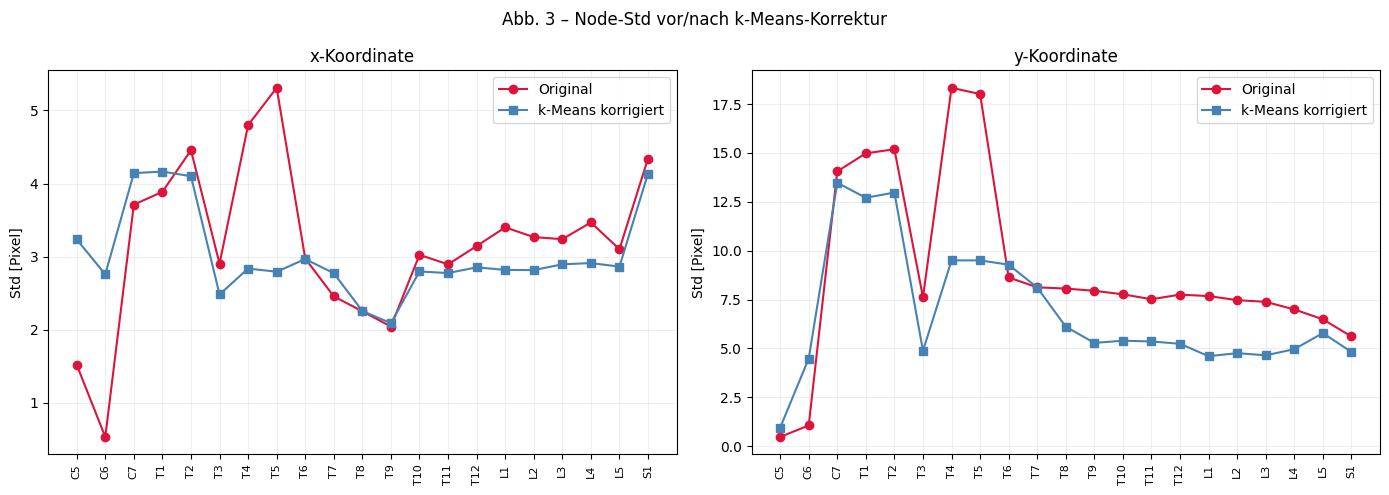

In [11]:
nodes_raw_elig = nodes_df_raw[nodes_df_raw['image_id'].isin(eligible_image_ids)]

std_raw  = compute_std_by_label(nodes_raw_elig)
std_corr = compute_std_by_label(nodes_eligible)

print(f'Ø Std raw:        x={std_raw["x_std"].mean():.2f} px, y={std_raw["y_std"].mean():.2f} px')
print(f'Ø Std korrigiert: x={std_corr["x_std"].mean():.2f} px, y={std_corr["y_std"].mean():.2f} px')

labels_present = std_raw.dropna(how='all').index.tolist()
x = range(len(labels_present))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
for ax, coord, title in zip(axes, ['x', 'y'], ['x-Koordinate', 'y-Koordinate']):
    ax.plot(x, std_raw.loc[labels_present, f'{coord}_std'].values,  'o-', color='crimson',    label='Original',         linewidth=1.5)
    ax.plot(x, std_corr.loc[labels_present, f'{coord}_std'].values, 's-', color='steelblue',  label='k-Means korrigiert', linewidth=1.5)
    ax.set_xticks(list(x))
    ax.set_xticklabels(labels_present, rotation=90, fontsize=8)
    ax.set_ylabel('Std [Pixel]')
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
fig.suptitle('Abb. 3 – Node-Std vor/nach k-Means-Korrektur', fontsize=12)
plt.tight_layout()
plt.savefig('output/node_std_before_after_correction.png', dpi=150)
plt.show()

### 2.2 ICC-Vergleich vor/nach Korrektur

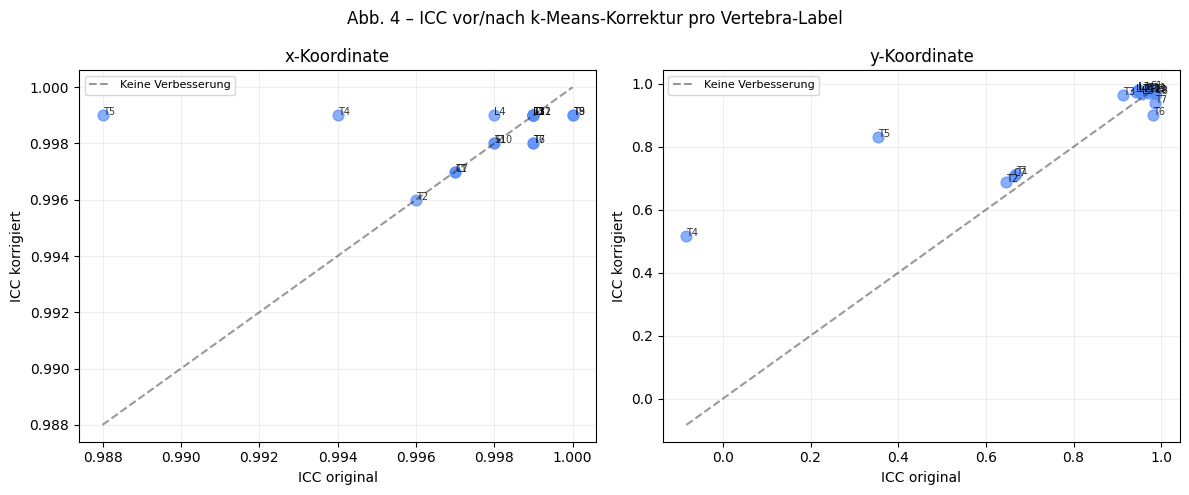

Wilcoxon x: stat=12.0, p=0.7257 (n=19 Labels)
Wilcoxon y: stat=43.0, p=0.0364 (n=19 Labels)


In [12]:
from scipy.stats import wilcoxon

icc_raw_rows = []
for label in spine_labels:
    label_data = nodes_raw_elig[nodes_raw_elig['vertebra_label'] == label]
    for coord in ['x', 'y']:
        res = compute_icc(label_data, 'image_id', 'rater_name', coord)
        icc_raw_rows.append({'vertebra_label': label, 'coord': coord, **res})

icc_raw_df = pd.DataFrame(icc_raw_rows)

# Scatterplot: ICC_original vs ICC_corrected
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, coord in zip(axes, ['x', 'y']):
    raw_icc  = icc_raw_df[icc_raw_df['coord'] == coord].set_index('vertebra_label')['ICC']
    corr_icc = icc_node_df[icc_node_df['coord'] == coord].set_index('vertebra_label')['ICC']
    merged = pd.DataFrame({'raw': raw_icc, 'corrected': corr_icc}).dropna()
    ax.scatter(merged['raw'], merged['corrected'], alpha=0.7, s=60)
    for label, row in merged.iterrows():
        ax.annotate(label, (row['raw'], row['corrected']), fontsize=7, alpha=0.8)
    lims = [min(merged.min()), max(merged.max())]
    ax.plot(lims, lims, 'k--', alpha=0.4, label='Keine Verbesserung')
    ax.set_xlabel('ICC original')
    ax.set_ylabel('ICC korrigiert')
    ax.set_title(f'{coord}-Koordinate')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.suptitle('Abb. 4 – ICC vor/nach k-Means-Korrektur pro Vertebra-Label', fontsize=12)
plt.tight_layout()
plt.savefig('output/icc_before_after_correction.png', dpi=150)
plt.show()

for coord in ['x', 'y']:
    raw_v  = icc_raw_df[icc_raw_df['coord'] == coord]['ICC'].dropna()
    corr_v = icc_node_df[icc_node_df['coord'] == coord]['ICC'].dropna()
    shared = raw_v.index.intersection(corr_v.index)
    if len(shared) >= 5:
        stat, p = wilcoxon(raw_v.loc[shared], corr_v.loc[shared])
        print(f'Wilcoxon {coord}: stat={stat:.1f}, p={p:.4f} (n={len(shared)} Labels)')

### 2.3 Charakterisierung der Labelling-Fehler

Fehlertypen: {'shift': 73, 'empty': 5}
Vorzeichen des Shift-Wertes:
  shift < 0 → Labels zu weit kaudal  (z. B. L1 statt T12) → kraniale Korrektur
  shift > 0 → Labels zu weit kranial (z. B. T12 statt L1)  → kaudale  Korrektur

Shift-Verteilung gesamt:
shift
-6     1
-2     3
-1    55
 0     1
 1    11
 2     1
 5     1

Shift-Fehler nach img_type:
shift          -6  -2  -1  0  1  2  5  Gesamt
img_type                                     
(unbekannt)     0   0   0  0  1  0  0       1
MRI-LWS-cor     0   0   5  0  2  0  0       7
Xray-LWS-ap     0   1  36  0  3  0  0      40
Xray-LWS-lat    0   0   7  0  3  1  0      11
Xray-LWS-recl   0   0   1  0  0  0  0       1
Xray-WS-ap      1   2   3  1  1  0  1       9
Xray-WS-lat     0   0   3  0  1  0  0       4


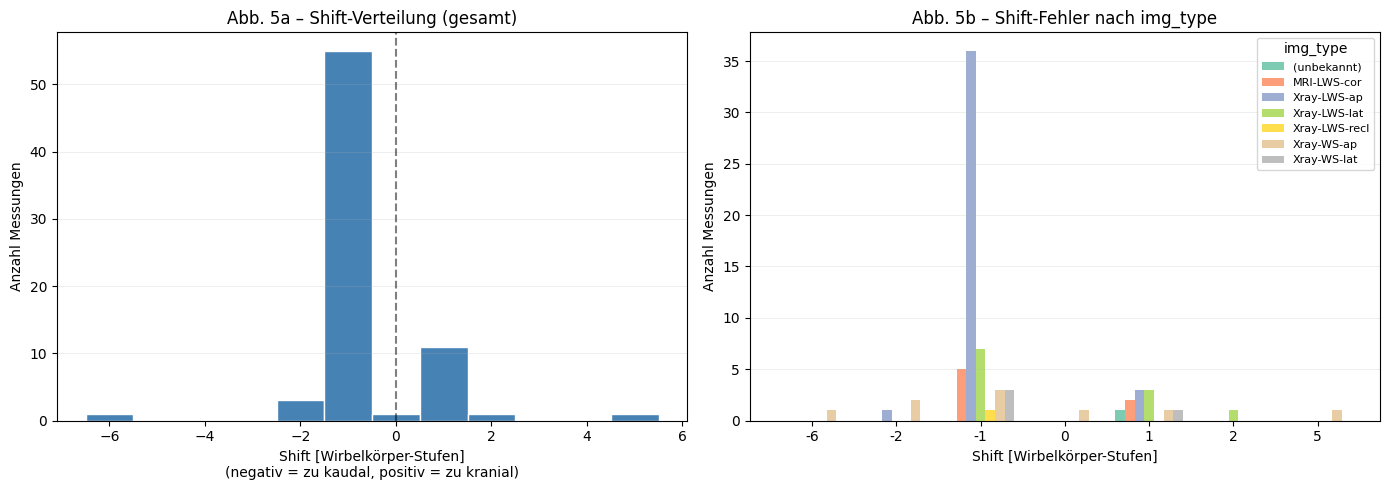

In [13]:
if len(label_errors) == 0:
    print('Keine Label-Fehler gefunden.')
else:
    print(f'Fehlertypen: {label_errors["error"].value_counts().to_dict()}')

    shift_errors = label_errors[label_errors['error'] == 'shift'].copy()
    if len(shift_errors) == 0:
        print('Keine Shift-Fehler.')
    else:
        # Vorzeichen-Erklärung
        # spine_labels ist kranial-zu-kaudal indiziert: C0=0, …, S1=25.
        # shift = assigned_label_index − label_index
        #
        #   shift < 0:  k-Means ordnet einen weiter kranial liegenden Wirbel zu, als der
        #               Annotator beschriftet hat. D.h. die Labels wurden zu weit kaudal
        #               gesetzt (z. B. L1 annotiert, obwohl es anatomisch T12 ist).
        #               Korrektur: Labels um |shift| Stufen kranialwärts verschieben.
        #
        #   shift > 0:  k-Means ordnet einen weiter kaudal liegenden Wirbel zu.
        #               Die Labels wurden zu weit kranial gesetzt (z. B. T12 annotiert,
        #               obwohl es anatomisch L1 ist).
        #               Korrektur: Labels um |shift| Stufen kaudalwärts verschieben.

        shift_errors['img_type'] = df4d.loc[shift_errors['df_idx'].values, 'img_type'].values
        shift_errors['img_type'] = shift_errors['img_type'].replace('', '(unbekannt)')

        print('Vorzeichen des Shift-Wertes:')
        print('  shift < 0 → Labels zu weit kaudal  (z. B. L1 statt T12) → kraniale Korrektur')
        print('  shift > 0 → Labels zu weit kranial (z. B. T12 statt L1)  → kaudale  Korrektur')

        print('\nShift-Verteilung gesamt:')
        print(shift_errors['shift'].value_counts().sort_index().to_string())

        print('\nShift-Fehler nach img_type:')
        ct = shift_errors.groupby(['img_type', 'shift']).size().unstack(fill_value=0)
        ct['Gesamt'] = ct.sum(axis=1)
        print(ct.to_string())

        # --- Abbildungen ---
        shift_vals = sorted(shift_errors['shift'].unique())
        img_types  = sorted(shift_errors['img_type'].unique())
        n_types    = len(img_types)
        colors     = plt.cm.Set2(np.linspace(0, 1, max(n_types, 1)))

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        # Abb. 5a – Gesamt-Histogramm
        ax = axes[0]
        bins = np.arange(min(shift_vals) - 0.5, max(shift_vals) + 1.5)
        ax.hist(shift_errors['shift'], bins=bins, color='steelblue', edgecolor='white')
        ax.axvline(0, color='black', linestyle='--', alpha=0.5)
        ax.set_xlabel('Shift [Wirbelkörper-Stufen]\n(negativ = zu kaudal, positiv = zu kranial)')
        ax.set_ylabel('Anzahl Messungen')
        ax.set_title('Abb. 5a – Shift-Verteilung (gesamt)')
        ax.grid(axis='y', alpha=0.3)

        # Abb. 5b – Grouped Bar nach img_type
        ax = axes[1]
        x       = np.arange(len(shift_vals))
        width   = 0.8 / max(n_types, 1)
        offsets = np.linspace(-(n_types - 1) * width / 2, (n_types - 1) * width / 2, n_types)
        for i, (itype, col) in enumerate(zip(img_types, colors)):
            sub    = shift_errors[shift_errors['img_type'] == itype]
            counts = [sub[sub['shift'] == s].shape[0] for s in shift_vals]
            ax.bar(x + offsets[i], counts, width, label=itype, color=col, alpha=0.85)
        ax.set_xticks(x)
        ax.set_xticklabels([str(s) for s in shift_vals])
        ax.set_xlabel('Shift [Wirbelkörper-Stufen]')
        ax.set_ylabel('Anzahl Messungen')
        ax.set_title('Abb. 5b – Shift-Fehler nach img_type')
        ax.legend(title='img_type', fontsize=8, loc='upper right')
        ax.grid(axis='y', alpha=0.3)

        plt.tight_layout()
        plt.savefig('output/label_shift_histogram.png', dpi=150)
        plt.show()

---
## Schritt 3 – Präzision der Winkelmessungen nach Technik
**Forschungsfrage:** Welche Mess-Technik liefert die höchste Inter-Rater-Konsistenz der Cobb-Winkel?

### 3A – Regionale Winkel: Spline vs. Cobb-regional vs. reconstructed_regional
Granularität: Pro Wirbelsäulenregion

Die drei `cobbType`-Varianten unterscheiden sich in der Messtechnik:

| cobbType | Quelle | Messprinzip |
|---|---|---|
| **Spline** | xray-annotator (TypeScript) | Winkel zwischen den Tangenten an der B-Spline-Kurve an den manuell platzierten Endpunkten. Die Kurve wird aus den Spline-Nodes interpoliert. |
| **Cobb-regional** | xray-annotator (TypeScript) | Klassischer Cobb-Winkel: Annotator zeichnet manuell je eine Gerade auf die Deckplatten des oberen und unteren Endwirbels (`stateObject.cobbLines`). Winkel zwischen diesen beiden Geraden. |
| **reconstructed_regional** | Python (`annotation_analysis.getReconstructedCobbAngles`) | Aus denselben Spline-Nodes wie `Spline` unabhängig in Python rekonstruierter regionaler Winkel (`interpolate_bspline` → `generate_COBB_angles_from_tangents(mode='regional_S1')`). Dient als Reproduktionskontrolle: stimmen TypeScript-Frontend und Python-Rekonstruktion überein? |

**Erwartung:** `Spline` ≈ `reconstructed_regional` (gleiche Nodes, gleiche Methode, verschiedene Implementierung). `Cobb-regional` kann systematisch abweichen, da er auf manuell platzierten Geraden statt auf der Spline-Kurve basiert.

In [ ]:
angles_eligible = angles_df[angles_df['image_id'].isin(eligible_image_ids)].copy()
angles_eligible['region_lower'] = angles_eligible['vertebra_lower'].map(label_to_region)
angles_eligible['region_upper'] = angles_eligible['vertebra_upper'].map(label_to_region)
angles_eligible['img_type'] = angles_eligible['img_type'].replace('', '(unbekannt)')

regional_types = ['Spline', 'Cobb-regional', 'reconstructed_regional']

# img_types mit >=10 eligible Bildern
it_counts = (
    angles_eligible[angles_eligible['cobbType'] == 'Spline']
    .groupby('img_type')['image_id'].nunique()
)
active_img_types = it_counts[it_counts >= 10].sort_values(ascending=False).index.tolist()

# --- Tab. 2a: ICC gesamt nach Technik × Region ---
regional_icc_rows = []
for cobb_type in regional_types:
    sub = angles_eligible[angles_eligible['cobbType'] == cobb_type]
    for region in spine_regions:
        res = compute_icc(sub[sub['region_lower'] == region], 'image_id', 'rater_name', 'angle')
        regional_icc_rows.append({'cobbType': cobb_type, 'region': region, **res})

regional_icc_df = pd.DataFrame(regional_icc_rows)
print('Tab. 2a – ICC(2,1) regionale Winkel nach Technik und Region (gesamt):')
print(regional_icc_df.pivot(index='region', columns='cobbType', values='ICC').round(3).to_string())

# Grouped Boxplot
colors = ['steelblue', 'coral', 'seagreen']
group_width, box_width = 0.8, 0.22
fig, ax = plt.subplots(figsize=(13, 5))
ticks, tick_labels = [], []
for ri, region in enumerate(spine_regions):
    center = ri * 1.2
    ticks.append(center)
    tick_labels.append(region)
    for ti, (ct, col) in enumerate(zip(regional_types, colors)):
        pts = angles_eligible[
            (angles_eligible['cobbType'] == ct) & (angles_eligible['region_lower'] == region)
        ]['angle'].dropna()
        pos = center + (ti - 1) * (group_width / len(regional_types))
        if len(pts) > 0:
            ax.boxplot(pts, positions=[pos], widths=box_width,
                       patch_artist=True, showfliers=False,
                       boxprops=dict(facecolor=col, alpha=0.6))
ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels)
ax.set_ylabel('Cobb-Winkel [°]')
ax.legend(handles=[Patch(facecolor=c, alpha=0.6, label=t) for c, t in zip(colors, regional_types)], fontsize=9)
ax.set_title('Abb. 6 – Regionale Cobb-Winkel nach Technik und Region (gesamt)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('output/regional_angles_boxplot.png', dpi=150)
plt.show()

# --- Tab. 2a-b: ICC nach Technik × img_type ---
it_pivot = aa.compute_icc_by_img_type(angles_eligible, regional_types, active_img_types)
print('\nTab. 2a-b – ICC(2,1) regionale Winkel nach img_type und Technik:')
print(it_pivot.round(3).to_string())

# Heatmap
fig, ax = plt.subplots(figsize=(9, max(3, len(active_img_types) * 0.65)))
hm_data = it_pivot[regional_types].values.astype(float)
im = ax.imshow(hm_data, cmap='RdYlGn', vmin=0.5, vmax=1.0, aspect='auto')
ax.set_xticks(range(len(regional_types)))
ax.set_xticklabels(regional_types, rotation=20, ha='right')
ax.set_yticks(range(len(active_img_types)))
ax.set_yticklabels(active_img_types)
for i in range(len(active_img_types)):
    for j in range(len(regional_types)):
        val = hm_data[i, j]
        if not np.isnan(val):
            ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=9,
                    color='white' if val < 0.65 else 'black')
plt.colorbar(im, ax=ax, label='ICC(2,1)')
ax.set_title('Abb. 6b – ICC regionale Winkel nach img_type und Technik')
plt.tight_layout()
plt.savefig('output/icc_regional_by_imgtype.png', dpi=150)
plt.show()


### 3B – Segmentale Winkel: Cobb-segmental vs. reconstructed_segmental
Granularität: Pro Wirbelkörperpaar

In [ ]:
segmental_types = ['Cobb-segmental', 'reconstructed_segmental']
seg_eligible = angles_eligible[angles_eligible['cobbType'].isin(segmental_types)].copy()

# --- ICC pro Vertebra-Paar (gesamt) ---
seg_icc_rows = []
for cobb_type in segmental_types:
    sub = seg_eligible[seg_eligible['cobbType'] == cobb_type]
    for (v_up, v_lo), group in sub.groupby(['vertebra_upper', 'vertebra_lower']):
        res = compute_icc(group, 'image_id', 'rater_name', 'angle', min_images=5)
        seg_icc_rows.append({'cobbType': cobb_type, 'vertebra_upper': v_up, 'vertebra_lower': v_lo, **res})

seg_icc_df = pd.DataFrame(seg_icc_rows).dropna(subset=['ICC'])
print(f'Segmentale Winkelpaare mit ICC-Ergebnis: {len(seg_icc_df)}')
print('\nTop 10 Paare nach ICC (Cobb-segmental):')
print(
    seg_icc_df[seg_icc_df['cobbType'] == 'Cobb-segmental']
    .sort_values('ICC', ascending=False)
    .head(10)
    [['vertebra_upper', 'vertebra_lower', 'ICC', 'CI95_lower', 'CI95_upper', 'n']]
    .to_string(index=False)
)
seg_icc_df.to_csv('output/icc_segmental_per_pair.csv', index=False)

# Heatmap ICC Cobb-segmental (gesamt)
seg_cs = seg_icc_df[seg_icc_df['cobbType'] == 'Cobb-segmental']
if len(seg_cs) > 0:
    active_labels = [l for l in spine_labels if
                     l in seg_cs['vertebra_upper'].values or l in seg_cs['vertebra_lower'].values]
    heatmap_data = pd.DataFrame(index=active_labels, columns=active_labels, dtype=float)
    for _, row in seg_cs.iterrows():
        if row['vertebra_upper'] in heatmap_data.index and row['vertebra_lower'] in heatmap_data.columns:
            heatmap_data.loc[row['vertebra_upper'], row['vertebra_lower']] = row['ICC']

    fig, ax = plt.subplots(figsize=(10, 8))
    hm = ax.imshow(heatmap_data.values.astype(float), cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(active_labels)))
    ax.set_xticklabels(active_labels, rotation=90, fontsize=8)
    ax.set_yticks(range(len(active_labels)))
    ax.set_yticklabels(active_labels, fontsize=8)
    ax.set_xlabel('vertebra_lower')
    ax.set_ylabel('vertebra_upper')
    plt.colorbar(hm, ax=ax, label='ICC(2,1)')
    ax.set_title('Abb. 7 – ICC Cobb-segmental nach Vertebra-Paar (gesamt)')
    plt.tight_layout()
    plt.savefig('output/icc_segmental_heatmap.png', dpi=150)
    plt.show()

# --- Aufschlüsselung nach img_type ---
it_seg_pivot = aa.compute_icc_by_img_type(seg_eligible, segmental_types, active_img_types)
print('\nTab. 2b-b – ICC(2,1) segmentale Winkel nach img_type und Technik:')
print(it_seg_pivot.round(3).to_string())

# Balkendiagramm
seg_colors = ['steelblue', 'coral']
x = np.arange(len(active_img_types))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 4))
for i, (ct, col) in enumerate(zip(segmental_types, seg_colors)):
    vals = [
        it_seg_pivot.loc[it, ct] if it in it_seg_pivot.index and ct in it_seg_pivot.columns
        else np.nan
        for it in active_img_types
    ]
    ax.bar(x + (i - 0.5) * width, vals, width, label=ct, color=col, alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(active_img_types, rotation=30, ha='right')
ax.set_ylabel('ICC(2,1)')
ax.set_ylim(0, 1.05)
ax.axhline(0.75, color='green', linestyle='--', alpha=0.5, label='gut (≥0.75)')
ax.legend(fontsize=9)
ax.set_title('Abb. 7b – ICC segmentale Winkel nach img_type und Technik')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('output/icc_segmental_by_imgtype.png', dpi=150)
plt.show()

### 3C – Vergleich aller Techniken

In [ ]:
all_types = ['Spline', 'Cobb-regional', 'Cobb-segmental', 'reconstructed_regional', 'reconstructed_segmental']

# --- Gesamt-Zusammenfassung ---
summary_rows = []
for ct in all_types:
    sub = angles_eligible[angles_eligible['cobbType'] == ct]
    res = compute_icc(sub, 'image_id', 'rater_name', 'angle', min_images=10)
    summary_rows.append({'cobbType': ct, **res})

summary_df = pd.DataFrame(summary_rows)
print('Tab. 2c – ICC(2,1) nach Messtechnik (gesamt):')
print(summary_df.round(3).to_string(index=False))
summary_df.to_csv('output/icc_summary_by_technique.csv', index=False)

# Violin-Plot
fig, ax = plt.subplots(figsize=(12, 5))
data_for_violin = [
    angles_eligible[angles_eligible['cobbType'] == ct]['angle'].dropna().values
    for ct in all_types
]
parts = ax.violinplot(data_for_violin, showmedians=True, showextrema=False)
for pc in parts['bodies']:
    pc.set_alpha(0.6)
ax.set_xticks(range(1, len(all_types) + 1))
ax.set_xticklabels(all_types, rotation=20, ha='right', fontsize=9)
ax.set_ylabel('Cobb-Winkel [°]')
ax.set_title('Abb. 8 – Winkelverteilung nach Messtechnik (gesamt)')
ax.grid(axis='y', alpha=0.3)

for i, row in enumerate(summary_rows):
    if not np.isnan(row['ICC']):
        ax.text(i + 1, ax.get_ylim()[1] * 0.97,
                f'ICC={row["ICC"]:.2f}', ha='center', va='top', fontsize=8, color='navy')

plt.tight_layout()
plt.savefig('output/angle_violin_by_technique.png', dpi=150)
plt.show()

# --- Aufschlüsselung nach img_type ---
it_all_pivot = aa.compute_icc_by_img_type(angles_eligible, all_types, active_img_types)
print('\nTab. 2c-b – ICC(2,1) nach img_type und Messtechnik:')
print(it_all_pivot.round(3).to_string())

# Heatmap: img_type × cobbType
fig, ax = plt.subplots(figsize=(12, max(3, len(active_img_types) * 0.65)))
hm_all = it_all_pivot[all_types].values.astype(float)
im = ax.imshow(hm_all, cmap='RdYlGn', vmin=0.5, vmax=1.0, aspect='auto')
ax.set_xticks(range(len(all_types)))
ax.set_xticklabels(all_types, rotation=20, ha='right')
ax.set_yticks(range(len(active_img_types)))
ax.set_yticklabels(active_img_types)
for i in range(len(active_img_types)):
    for j in range(len(all_types)):
        val = hm_all[i, j]
        if not np.isnan(val):
            ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=9,
                    color='white' if val < 0.65 else 'black')
plt.colorbar(im, ax=ax, label='ICC(2,1)')
ax.set_title('Abb. 8b – ICC nach img_type und Messtechnik')
plt.tight_layout()
plt.savefig('output/icc_all_by_imgtype.png', dpi=150)
plt.show()

---
## Schritt 4 – Variabilität der Endpunkt-Auswahl (vertebra_upper / vertebra_lower)
**Forschungsfrage:** Wie konsistent wählen verschiedene Annotator\*innen die Wirbelsäulengrenzen ihres Messbereichs, und welche Winkel-Endpunkte werden übereinstimmend gemessen?

Es gibt zwei Ebenen der Endpunkt-Variabilität:
- **Messbereich** (`vertebra_range`): der vom Annotator beabsichtigte Bereich der Wirbelsäule (vr_start bis vr_end)
- **Winkel-Endpunkte** (`vertebra_upper`/`vertebra_lower`): die konkreten Wirbelkörperpaare, für die ein Cobb-Winkel eingetragen wurde

### 4.1 – Vertebra-Range des Messbereichs (vr_start / vr_end)

vr_eligible: 1019 Messungen, 387 Bilder

Tab. 3a – Häufigste vr_start_label (obere Grenze):
vr_start_label
T10    285
T11    244
T9     165
T12    115
T8      78
T7      30
L1      22
C7      20
C6      11
T6      11

Tab. 3a – Häufigste vr_end_label (untere Grenze):
vr_end_label
S1     945
L5      65
L4       6
L3       2
T12      1

Spann-Statistik: Ø=8.5 ± 2.7, min=4, max=24

Tab. 3b – ICC(2,1) der Messbereich-Parameter:
  vr_start : ICC=0.916  [0.901, 0.930]  n=387
  vr_end   : ICC=0.237  [0.165, 0.312]  n=387
  span     : ICC=0.899  [0.882, 0.916]  n=387
  (Hinweis: vr_end zeigt geringen ICC trotz hoher Übereinstimmung, da fast alle Rater S1 wählen
   → geringe Bild-zu-Bild-Varianz → ICC nahe 0 trotz faktischer Konsistenz.)

Tab. 3c – Häufigkeit von Endpunkt-Abweichungen (>= 2 Rater):
  vr_start (obere Grenze): 202/387 Bilder mit Abweichung (52.2%)
  vr_end (untere Grenze): 57/387 Bilder mit Abweichung (14.7%)


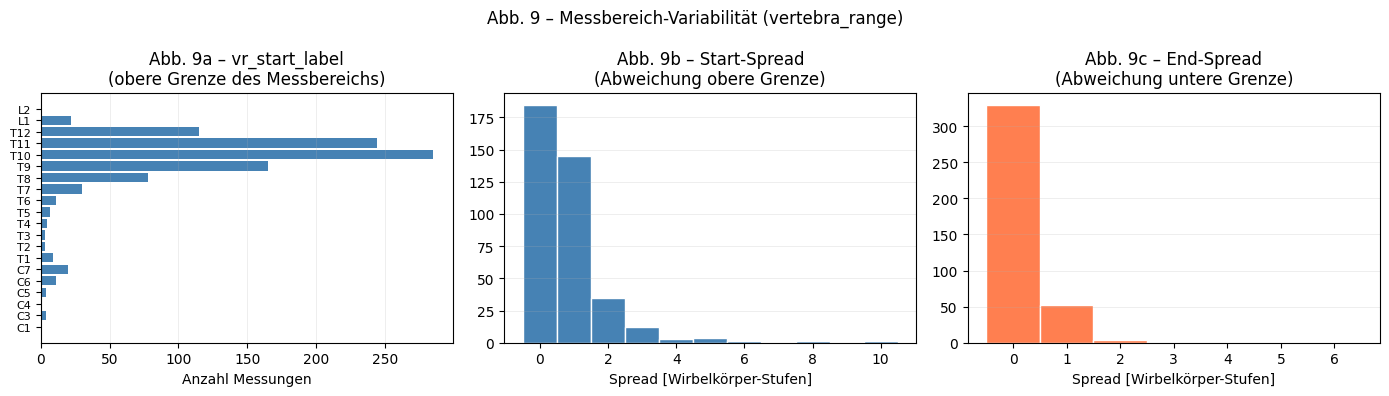


Tab. 3d – ICC der Messbereich-Parameter nach img_type:
parameter      vr_start   span  vr_end
img_type                              
MRI-LWS-cor       0.619  0.332   0.301
MRI-LWS-sag       0.935  0.935  -1.000
Xray-LWS-ap       0.836  0.765   0.194
Xray-LWS-incl     0.782  0.782  -0.298
Xray-LWS-lat      0.742  0.728   0.155
Xray-LWS-recl     0.913  0.896  -0.062
Xray-WS-ap        0.679  0.634  -0.100


In [17]:
label_to_idx = {l: i for i, l in enumerate(spine_labels)}

vr_df      = aa.build_vertebra_range_df(df4d_corrected)
vr_eligible = vr_df[vr_df['image_id'].isin(eligible_image_ids)].copy()
vr_eligible['img_type'] = vr_eligible['img_type'].replace('', '(unbekannt)')

print(f'vr_eligible: {len(vr_eligible)} Messungen, {vr_eligible["image_id"].nunique()} Bilder')

# --- Tab. 3a: Deskriptive Statistik Messbereich ---
print('\nTab. 3a – Häufigste vr_start_label (obere Grenze):')
print(vr_eligible['vr_start_label'].value_counts().head(10).to_string())
print('\nTab. 3a – Häufigste vr_end_label (untere Grenze):')
print(vr_eligible['vr_end_label'].value_counts().head(10).to_string())
print(f'\nSpann-Statistik: Ø={vr_eligible["span"].mean():.1f} ± {vr_eligible["span"].std():.1f}, '
      f'min={vr_eligible["span"].min()}, max={vr_eligible["span"].max()}')

# --- Tab. 3b: ICC der Endpunkt-Indizes ---
icc_start = compute_icc(vr_eligible, 'image_id', 'rater_name', 'vr_start', min_images=10)
icc_end   = compute_icc(vr_eligible, 'image_id', 'rater_name', 'vr_end',   min_images=10)
icc_span  = compute_icc(vr_eligible, 'image_id', 'rater_name', 'span',     min_images=10)
print('\nTab. 3b – ICC(2,1) der Messbereich-Parameter:')
print(f'  vr_start : ICC={icc_start["ICC"]:.3f}  [{icc_start["CI95_lower"]:.3f}, {icc_start["CI95_upper"]:.3f}]  n={icc_start["n"]}')
print(f'  vr_end   : ICC={icc_end["ICC"]:.3f}  [{icc_end["CI95_lower"]:.3f}, {icc_end["CI95_upper"]:.3f}]  n={icc_end["n"]}')
print(f'  span     : ICC={icc_span["ICC"]:.3f}  [{icc_span["CI95_lower"]:.3f}, {icc_span["CI95_upper"]:.3f}]  n={icc_span["n"]}')
print('  (Hinweis: vr_end zeigt geringen ICC trotz hoher Übereinstimmung, da fast alle Rater S1 wählen'
      '\n   → geringe Bild-zu-Bild-Varianz → ICC nahe 0 trotz faktischer Konsistenz.)')

# --- Tab. 3c: Spread-Analyse pro Bild ---
spread_rows = []
for img_id, group in vr_eligible.groupby('image_id'):
    if group['rater_name'].nunique() < 2:
        continue
    spread_rows.append({
        'image_id':     img_id,
        'img_type':     group['img_type'].iloc[0],
        'n_raters':     group['rater_name'].nunique(),
        'start_spread': group['vr_start'].max() - group['vr_start'].min(),
        'end_spread':   group['vr_end'].max()   - group['vr_end'].min(),
        'span_std':     group['span'].std(),
    })
spread_df = pd.DataFrame(spread_rows)

print('\nTab. 3c – Häufigkeit von Endpunkt-Abweichungen (>= 2 Rater):')
for col, label in [('start_spread', 'vr_start (obere Grenze)'), ('end_spread', 'vr_end (untere Grenze)')]:
    n_any = (spread_df[col] > 0).sum()
    pct   = 100 * n_any / len(spread_df)
    print(f'  {label}: {n_any}/{len(spread_df)} Bilder mit Abweichung ({pct:.1f}%)')

# --- Visualisierung ---
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Histogramm vr_start_label
ax = axes[0]
labels_cranial = [l for l in spine_labels if l in vr_eligible['vr_start_label'].values]
counts_start = vr_eligible['vr_start_label'].value_counts().reindex(labels_cranial, fill_value=0)
ax.barh(range(len(counts_start)), counts_start.values, color='steelblue')
ax.set_yticks(range(len(counts_start)))
ax.set_yticklabels(counts_start.index, fontsize=8)
ax.set_xlabel('Anzahl Messungen')
ax.set_title('Abb. 9a – vr_start_label\n(obere Grenze des Messbereichs)')
ax.grid(axis='x', alpha=0.3)

# Histogramm start_spread
ax = axes[1]
spread_vals = sorted(spread_df['start_spread'].unique())
bins = np.arange(-0.5, max(spread_vals) + 1.5)
ax.hist(spread_df['start_spread'], bins=bins, color='steelblue', edgecolor='white')
ax.set_xlabel('Spread [Wirbelkörper-Stufen]')
ax.set_title('Abb. 9b – Start-Spread\n(Abweichung obere Grenze)')
ax.grid(axis='y', alpha=0.3)

# Histogramm end_spread
ax = axes[2]
end_vals = sorted(spread_df['end_spread'].unique())
bins_end = np.arange(-0.5, max(end_vals) + 1.5)
ax.hist(spread_df['end_spread'], bins=bins_end, color='coral', edgecolor='white')
ax.set_xlabel('Spread [Wirbelkörper-Stufen]')
ax.set_title('Abb. 9c – End-Spread\n(Abweichung untere Grenze)')
ax.grid(axis='y', alpha=0.3)

plt.suptitle('Abb. 9 – Messbereich-Variabilität (vertebra_range)', fontsize=12)
plt.tight_layout()
plt.savefig('output/vertebra_range_spread.png', dpi=150)
plt.show()

# --- Aufschlüsselung nach img_type ---
it_vr_rows = []
for img_type in active_img_types:
    sub_it = vr_eligible[vr_eligible['img_type'] == img_type]
    for param, col in [('vr_start', 'vr_start'), ('vr_end', 'vr_end'), ('span', 'span')]:
        res = compute_icc(sub_it, 'image_id', 'rater_name', col, min_images=5)
        it_vr_rows.append({'img_type': img_type, 'parameter': param, **res})

it_vr_df = pd.DataFrame(it_vr_rows)
print('\nTab. 3d – ICC der Messbereich-Parameter nach img_type:')
print(it_vr_df.pivot(index='img_type', columns='parameter', values='ICC')[['vr_start', 'span', 'vr_end']].round(3).to_string())

### 4.2 – Winkel-Endpunkt-Übereinstimmung (vertebra_upper / vertebra_lower)

Verschiedene Annotator\*innen können für dasselbe Bild unterschiedliche Wirbelkörperpaare als Winkelendpunkte wählen – z. B. misst ein Rater den Winkel T12→S1, ein anderer T11→S1. Ob die gemessenen Winkel überhaupt vergleichbar sind, hängt davon ab, wie stark diese Endpunkte voneinander abweichen.

**Jaccard-Ähnlichkeit** quantifiziert die Übereinstimmung der gemessenen Winkelpaare zwischen Ratern:

$$J = \frac{|\text{Schnittmenge}|}{|\text{Vereinigung}|}$$

Für ein Bild mit zwei Ratern:
- Rater A misst Paare {T12→L3, L2→S1}
- Rater B misst Paare {T11→L3, L2→S1}
- Schnittmenge = {L2→S1} → |Schnittmenge| = 1
- Vereinigung = {T12→L3, T11→L3, L2→S1} → |Vereinigung| = 3
- **J = 1/3 ≈ 0.33**

Wertebereich: J = 1.0 → alle Rater haben exakt dieselben Paare gemessen; J = 0 → keine gemeinsamen Paare.

Tab. 4a – Jaccard-Übereinstimmung der Winkel-Endpunkte nach cobbType:
                         n_images  full_consensus  pct_consensus  jaccard_mean  jaccard_std
cobbType                                                                                   
Cobb-regional                 377              92           24.4         0.260        0.429
Cobb-segmental                374              30            8.0         0.513        0.219
Spline                        386              66           17.1         0.226        0.373
reconstructed_regional        360              59           16.4         0.241        0.369
reconstructed_segmental       386             315           81.6         0.965        0.081


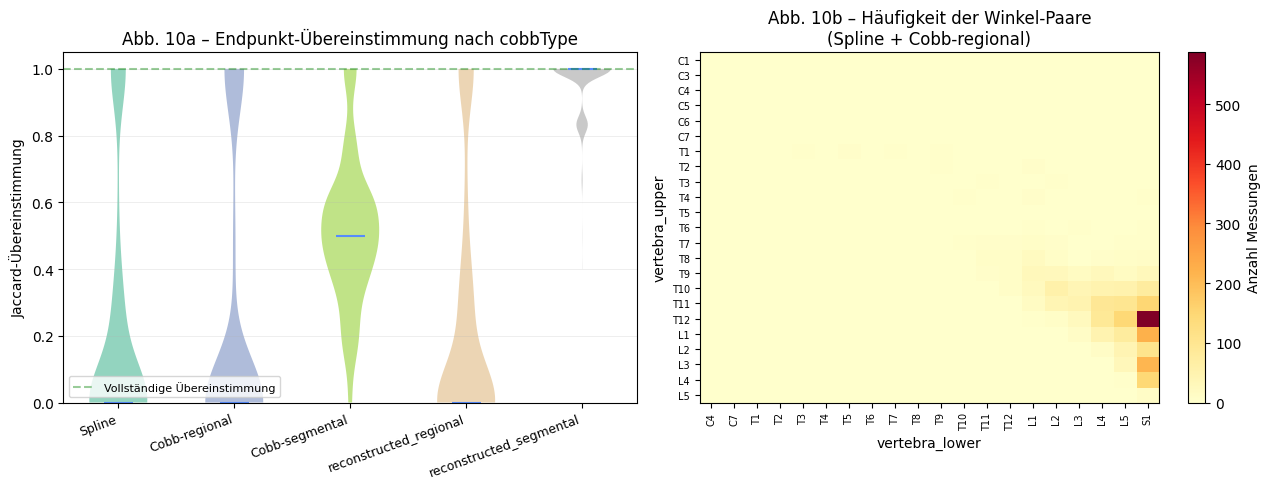


Tab. 4b – Ø Jaccard nach cobbType und img_type:
cobbType       Spline  Cobb-regional  Cobb-segmental  reconstructed_regional  reconstructed_segmental
img_type                                                                                             
MRI-LWS-cor     0.178          0.120           0.470                   0.249                    0.873
MRI-LWS-sag     0.483          0.846           0.723                   0.389                    1.000
Xray-LWS-ap     0.193          0.038           0.493                   0.185                    0.965
Xray-LWS-incl   0.352          0.500           0.519                   0.247                    0.991
Xray-LWS-lat    0.254          0.462           0.531                   0.283                    0.978
Xray-LWS-recl   0.227          0.407           0.566                   0.343                    0.991
Xray-WS-ap      0.132          0.000           0.443                   0.106                    0.925


In [18]:
# Für jedes (image_id, cobbType) mit >=2 Ratern: Jaccard-Ähnlichkeit der
# (vertebra_upper, vertebra_lower)-Paare über Rater hinweg.
# Jaccard = |Schnittmenge| / |Vereinigung| der gemessenen Paare.
# Jaccard = 1.0  → alle Rater haben identische Winkelpaare gemessen.
# Jaccard < 1.0  → mindestens ein Rater hat abweichende Endpunkte gewählt.

jaccard_rows = []
for (img_id, cobb_type), group in angles_eligible.groupby(['image_id', 'cobbType']):
    raters = group['rater_name'].unique()
    if len(raters) < 2:
        continue
    rater_pairs = {
        r: set(zip(group[group['rater_name'] == r]['vertebra_upper'],
                   group[group['rater_name'] == r]['vertebra_lower']))
        for r in raters
    }
    pairs_list = list(rater_pairs.values())
    intersection = pairs_list[0].copy()
    union        = pairs_list[0].copy()
    for p in pairs_list[1:]:
        intersection &= p
        union        |= p
    jaccard = len(intersection) / len(union) if union else 1.0
    jaccard_rows.append({
        'image_id':       img_id,
        'img_type':       group['img_type'].iloc[0],
        'cobbType':       cobb_type,
        'n_raters':       len(raters),
        'n_shared_pairs': len(intersection),
        'n_total_pairs':  len(union),
        'jaccard':        jaccard,
        'full_consensus': jaccard == 1.0,
    })

jaccard_df = pd.DataFrame(jaccard_rows)

print('Tab. 4a – Jaccard-Übereinstimmung der Winkel-Endpunkte nach cobbType:')
jac_summary = (
    jaccard_df.groupby('cobbType')
    .agg(
        n_images      =('image_id',       'count'),
        full_consensus=('full_consensus',  'sum'),
        pct_consensus =('full_consensus',  'mean'),
        jaccard_mean  =('jaccard',         'mean'),
        jaccard_std   =('jaccard',         'std'),
    )
    .round(3)
)
jac_summary['pct_consensus'] = (jac_summary['pct_consensus'] * 100).round(1)
jac_summary['full_consensus'] = jac_summary['full_consensus'].astype(int)
print(jac_summary.to_string())

# --- Visualisierung ---
cobb_order = ['Spline', 'Cobb-regional', 'Cobb-segmental', 'reconstructed_regional', 'reconstructed_segmental']
cobb_present = [c for c in cobb_order if c in jaccard_df['cobbType'].values]
colors_jac = plt.cm.Set2(np.linspace(0, 1, len(cobb_present)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Abb. 10a – Boxplot Jaccard per cobbType
ax = axes[0]
data_jac = [jaccard_df[jaccard_df['cobbType'] == ct]['jaccard'].values for ct in cobb_present]
parts = ax.violinplot(data_jac, showmedians=True, showextrema=False)
for pc, col in zip(parts['bodies'], colors_jac):
    pc.set_facecolor(col)
    pc.set_alpha(0.7)
ax.set_xticks(range(1, len(cobb_present) + 1))
ax.set_xticklabels(cobb_present, rotation=20, ha='right', fontsize=9)
ax.set_ylabel('Jaccard-Übereinstimmung')
ax.set_ylim(0, 1.05)
ax.set_title('Abb. 10a – Endpunkt-Übereinstimmung nach cobbType')
ax.axhline(1.0, color='green', linestyle='--', alpha=0.4, label='Vollständige Übereinstimmung')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# Abb. 10b – Verteilung der Winkel-Endpunkte (vertebra_upper × vertebra_lower)
# für regionale Winkeltypen (Spline, Cobb-regional): Heatmap der häufigsten Paare
ax = axes[1]
regional_pairs = angles_eligible[
    angles_eligible['cobbType'].isin(['Spline', 'Cobb-regional'])
].copy()
regional_pairs['upper_idx'] = regional_pairs['vertebra_upper'].map(label_to_idx)
regional_pairs['lower_idx'] = regional_pairs['vertebra_lower'].map(label_to_idx)
pair_counts = regional_pairs.groupby(['vertebra_upper', 'vertebra_lower']).size().reset_index(name='n')

# Pivot für Heatmap
active_up = [l for l in spine_labels if l in pair_counts['vertebra_upper'].values]
active_lo = [l for l in spine_labels if l in pair_counts['vertebra_lower'].values]
hm = pd.DataFrame(0, index=active_up, columns=active_lo)
for _, row in pair_counts.iterrows():
    if row['vertebra_upper'] in hm.index and row['vertebra_lower'] in hm.columns:
        hm.loc[row['vertebra_upper'], row['vertebra_lower']] = row['n']

im = ax.imshow(hm.values.astype(float), cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(active_lo)))
ax.set_xticklabels(active_lo, rotation=90, fontsize=7)
ax.set_yticks(range(len(active_up)))
ax.set_yticklabels(active_up, fontsize=7)
ax.set_xlabel('vertebra_lower')
ax.set_ylabel('vertebra_upper')
plt.colorbar(im, ax=ax, label='Anzahl Messungen')
ax.set_title('Abb. 10b – Häufigkeit der Winkel-Paare\n(Spline + Cobb-regional)')

plt.tight_layout()
plt.savefig('output/endpoint_jaccard_and_heatmap.png', dpi=150)
plt.show()

# --- Aufschlüsselung nach img_type ---
print('\nTab. 4b – Ø Jaccard nach cobbType und img_type:')
jac_it = (
    jaccard_df[jaccard_df['img_type'].isin(active_img_types)]
    .groupby(['img_type', 'cobbType'])['jaccard']
    .mean()
    .unstack(fill_value=np.nan)
)
print(jac_it[[c for c in cobb_order if c in jac_it.columns]].round(3).to_string())

---
## Schritt 5 – Geometrisch-abgeleitete Cobb-Winkel (Inflektionspunkt-Methode)

**Motivation:** Section 4.2 zeigt: nur 17–24 % vollständige Endpunkt-Übereinstimmung (Jaccard) bei Spline- und regionalen Cobb-Winkeln. Rater messen verschiedene Kurvenabschnitte, obwohl ihre Node-Positionen hoch konsistent sind (ICC x ≈ 0.999, y ≈ 0.974). Die subjektive Endpunkt-Wahl ist der Haupttreiber der ICC-Verringerung.

**Ansatz:** Winkelgrenzen werden nicht durch Rater-Wahl, sondern durch die **Geometrie der rekonstruierten Spline** bestimmt: lokale Extrema des Tangentenwinkels (Richtungswechsel = Inflektionspunkte). Diese sind deterministisch aus den Nodes berechenbar – ohne subjektive Endpunkt-Entscheidung.

**Algorithmus:**
1. Spline aus Nodes rekonstruieren (`interpolate_bspline`, `num_steps=200`)
2. Tangentenwinkel an den **Nodes** berechnen (8–10 Punkte, kein Smoothing)
3. Lokale Extrema beider Vorzeichen (Maxima + Minima) → Richtungswechsel
4. Mapping der Knoten-Positionen auf die dichte Spline → präzise Perpendikulare
5. Cobb-Winkel zwischen je zwei aufeinanderfolgenden Perpendikularen
6. Winkel < `MIN_INFLECTION_ANGLE` verwerfen; verbleibende von oben neu nummerieren: `inflection_r0`, `inflection_r1`, …

**Was bedeutet der Rang?**

`inflection_r0` ist der **erste klinisch relevante Winkel von kranial**, d. h. der erste Krümmungsabschnitt, dessen Winkel den Schwellwert `MIN_INFLECTION_ANGLE` überschreitet. `inflection_r1` ist der nächstfolgende Abschnitt usw. Die Nummerierung ist **positional, nicht anatomisch** – `inflection_r0` entspricht nicht zwingend demselben Wirbelsäulenabschnitt bei verschiedenen Ratern oder Bildern.

Dies hat eine wichtige Konsequenz: Wenn Rater A einen größeren Messbereich wählt als Rater B, können kleine Randwinkel am kranialen Ende die Nummerierung verschieben – `inflection_r0` würde dann für diese beiden Rater verschiedene Kurvenabschnitte messen. Ein höherer `MIN_INFLECTION_ANGLE`-Schwellwert reduziert diesen Effekt, indem kleine Grenzwinkel herausgefiltert werden (bei 10° erreicht `inflection_r1` ≈ 0.80 ICC).

**ICC-Matching-Strategie (Maximaler gemeinsamer Rang):** Für jedes Bild werden nur die Ränge in die ICC einbezogen, die **alle Rater** dieses Bildes aufweisen (= Minimum der maximalen Ränge über Rater). Damit wird sichergestellt, dass pro Rang immer alle Rater einen Wert beitragen – kein Imputation, kein Missing-Value-Problem.

### 5.1 – Diagnostik: Verteilung der Inflektionspunkte

MIN_INFLECTION_ANGLE = 10.0°
inflection_df_raw:   2553 Zeilen gesamt
inflection_eligible: 2317 Zeilen (eligible Bilder)
cobbTypes: {'inflection_r0': 1035, 'inflection_r1': 845, 'inflection_r2': 408, 'inflection_r3': 166, 'inflection_r4': 55, 'inflection_r5': 27, 'inflection_r6': 12, 'inflection_r7': 3, 'inflection_r8': 2}

Tab. 5-D – Verteilung der Inflektions-Winkel pro Rater×Bild:
n_angles
1    170
2    404
3    226
4    105
5     25
6      8
7      6
8      1
9      2

Ø 2.45 ± 1.16 Winkel pro Messung (Median 2)


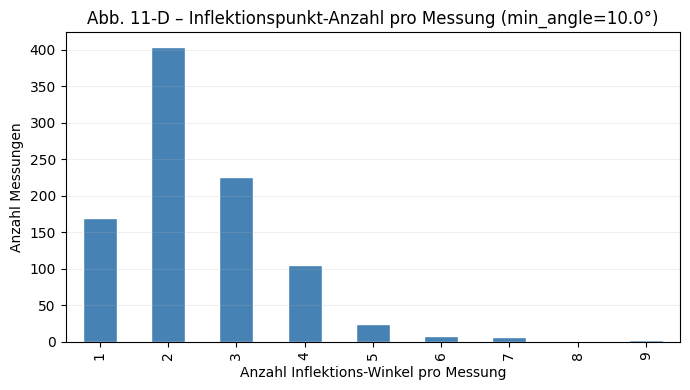

In [32]:
MIN_INFLECTION_ANGLE = 10.0  # Schwellwert: Winkel unterhalb werden verworfen

inflection_df_raw = aa.build_angles_df(
    df4d_corrected,
    include_reconstructed=False,
    include_inflection=True,
    min_inflection_angle=MIN_INFLECTION_ANGLE,
)

# Nur inflection_r*-Zeilen behalten (build_angles_df schließt immer die Original-Winkel ein)
inflection_df_raw = inflection_df_raw[
    inflection_df_raw['cobbType'].str.startswith('inflection_')
].copy()

inflection_eligible = (
    inflection_df_raw[inflection_df_raw['image_id'].isin(eligible_image_ids)]
    .copy()
)
inflection_eligible['img_type'] = inflection_eligible['img_type'].replace('', '(unbekannt)')

print(f'MIN_INFLECTION_ANGLE = {MIN_INFLECTION_ANGLE}°')
print(f'inflection_df_raw:   {len(inflection_df_raw)} Zeilen gesamt')
print(f'inflection_eligible: {len(inflection_eligible)} Zeilen (eligible Bilder)')
print(f'cobbTypes: {dict(sorted(inflection_df_raw["cobbType"].value_counts().items()))}')

# Anzahl Inflektions-Winkel pro Messung (image_id × rater_name)
rank_counts = (
    inflection_eligible
    .groupby(['image_id', 'rater_name'])['cobbType']
    .count()
    .rename('n_angles')
)
print('\nTab. 5-D – Verteilung der Inflektions-Winkel pro Rater×Bild:')
print(rank_counts.value_counts().sort_index().rename('Anzahl Messungen').to_string())
print(f'\nØ {rank_counts.mean():.2f} ± {rank_counts.std():.2f} Winkel pro Messung '
      f'(Median {rank_counts.median():.0f})')

fig, ax = plt.subplots(figsize=(7, 4))
rank_counts.value_counts().sort_index().plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_xlabel('Anzahl Inflektions-Winkel pro Messung')
ax.set_ylabel('Anzahl Messungen')
ax.set_title(f'Abb. 11-D – Inflektionspunkt-Anzahl pro Messung (min_angle={MIN_INFLECTION_ANGLE}°)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('output/inflection_rank_distribution.png', dpi=150)
plt.show()


### 5.2 – ICC pro Inflektions-Rang (Maximaler gemeinsamer Rang)

In [ ]:
# ---- Max-Common-Rank-Strategie ----
inflection_filtered = aa.filter_inflection_max_common_rank(inflection_eligible)
print(f'inflection_filtered: {len(inflection_filtered)} Zeilen nach Max-Common-Rank-Filterung')

inflection_ranks = sorted(
    inflection_filtered['cobbType'].unique(),
    key=lambda x: int(x.split('_r')[-1])
)

# ICC pro Rang
icc_infl_rows = []
for cobb_type in inflection_ranks:
    sub = inflection_filtered[inflection_filtered['cobbType'] == cobb_type]
    res = compute_icc(sub, 'image_id', 'rater_name', 'angle', min_images=10)
    icc_infl_rows.append({'cobbType': cobb_type, **res})

icc_infl_df = pd.DataFrame(icc_infl_rows).dropna(subset=['ICC'])
print('\nTab. 5a – ICC(2,1) pro Inflektions-Rang (Max-Common-Rank):')
print(icc_infl_df.round(3).to_string(index=False))

# Referenzwerte aus Section 3C
ref_types = ['Spline', 'Cobb-regional', 'reconstructed_regional']
ref_rows = []
for ct in ref_types:
    sub = angles_eligible[angles_eligible['cobbType'] == ct]
    res = compute_icc(sub, 'image_id', 'rater_name', 'angle', min_images=10)
    ref_rows.append({'cobbType': ct, **res})
ref_df = pd.DataFrame(ref_rows)

all_for_plot = pd.concat([icc_infl_df, ref_df], ignore_index=True)

# Balkendiagramm
fig, ax = plt.subplots(figsize=(10, 4))
colors_bar = ['steelblue' if 'inflection' in ct else 'coral' for ct in all_for_plot['cobbType']]
ax.bar(range(len(all_for_plot)), all_for_plot['ICC'], color=colors_bar, alpha=0.85)
ax.errorbar(
    range(len(all_for_plot)), all_for_plot['ICC'],
    yerr=[
        (all_for_plot['ICC'] - all_for_plot['CI95_lower']).clip(lower=0),
        (all_for_plot['CI95_upper'] - all_for_plot['ICC']).clip(lower=0),
    ],
    fmt='none', color='black', capsize=4
)
ax.set_xticks(range(len(all_for_plot)))
ax.set_xticklabels(all_for_plot['cobbType'], rotation=25, ha='right', fontsize=9)
ax.set_ylabel('ICC(2,1)')
ax.set_ylim(0, 1.05)
ax.axhline(0.75, color='green', linestyle='--', alpha=0.5, label='gut (≥0.75)')
ax.legend(
    handles=[
        Patch(facecolor='steelblue', alpha=0.85, label='inflection_r* (neu)'),
        Patch(facecolor='coral',     alpha=0.85, label='Referenz-cobbTypes'),
    ],
    fontsize=9
)
ax.set_title('Abb. 11 – ICC pro Inflektions-Rang vs. Referenz-Methoden')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('output/icc_inflection_by_rank.png', dpi=150)
plt.show()

### 5.3 – ICC nach Bildtyp (img_type)

In [ ]:
# ICC Inflektions-Rang × img_type
display_ranks = [c for c in inflection_ranks if c in inflection_filtered['cobbType'].values]
display_ranks = display_ranks[:5]  # maximal 5 Ränge

it_infl_pivot = aa.compute_icc_by_img_type(inflection_filtered, display_ranks, active_img_types)
print('Tab. 5b – ICC Inflektions-Winkel nach img_type und Rang:')
infl_cols = [c for c in display_ranks if c in it_infl_pivot.columns]
print(it_infl_pivot[infl_cols].round(3).to_string())

# Heatmap
fig, ax = plt.subplots(figsize=(max(6, len(infl_cols) * 1.5), max(3, len(active_img_types) * 0.65)))
hm_infl = it_infl_pivot[infl_cols].values.astype(float)
im = ax.imshow(hm_infl, cmap='RdYlGn', vmin=0.4, vmax=1.0, aspect='auto')
ax.set_xticks(range(len(infl_cols)))
ax.set_xticklabels(infl_cols, rotation=20, ha='right')
ax.set_yticks(range(len(active_img_types)))
ax.set_yticklabels(active_img_types)
for i in range(len(active_img_types)):
    for j in range(len(infl_cols)):
        val = hm_infl[i, j]
        if not np.isnan(val):
            ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=9,
                    color='white' if val < 0.6 else 'black')
plt.colorbar(im, ax=ax, label='ICC(2,1)')
ax.set_title('Abb. 11b – ICC Inflektions-Winkel nach img_type und Rang')
plt.tight_layout()
plt.savefig('output/icc_inflection_by_imgtype.png', dpi=150)
plt.show()